# Evolution of star clusters in arbitrary tidal fields
Florent Renaud, Mark Gieles, Christian Boily. 2011
doi:10.1111/j.1365-2966.2011.19531.x

## Goal

- play with the results of the paper 
- make some jacobi surfaces 
- make an animation of a surface in the cluster frame 
- make an animation of the football flying through space 

In [139]:
import numpy, matplotlib.pyplot as plt, agama, os
agama.setUnits(mass=1, length=1, velocity=1)
import sympy as sp 
from matplotlib import patches
from skimage import measure
from skimage.draw import ellipsoid
from astropy import constants as cnst 
from astropy import units as u 
from scipy.optimize import root,fsolve,brentq

plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{txfonts}",
})

## The equations

Hello, my goal is to write a code to compute the jacobii surface of a cluster in an arbitrary potential numerically. I'm following this paper where they first derive the acceleration of a particle in the non-inertial reference frame centered on the star cluster: 

$$ \frac{d^2 \mathbf{r}}{dt^2} = -\nabla \phi_c(\mathbf{r}) + \mathbf{T}_t (\mathbf{r})\cdot\mathbf{r} - \Omega \times (\Omega \times \mathbf{r}) - \frac{d\Omega}{dt}\times \mathbf{r} - 2\mathbf{\Omega}\times\frac{d\mathbf{r}}{dt}$$

First. I think this paper has a mistake? if we're in the frame centered on teh cluster, and $\mathbf{r}$ is the position of a particle relative to the cluster's center of mass... Then, $\mathbf{r}$ cannot also be the argument for the tidal tensor, correct? the tidal tensor's argument is the position of the globular cluster. Because, we linearlize the galaxy's gravitational field about the position of the cluster... $F_{\mathrm{gal}} \approx \mathbf{T}(\mathbf{r}_\mathrm{gc})\cdot d\mathbf{r}$ where $d\mathbf{r} = r_{\mathrm{star}}-\mathbf{r}_\mathrm{gc}$

My goal is to write a code that can numerically find the jacobi surface for any cluster potential, any galactic potential, and return it's orientation. I'm confused on how to do this. Next, the paper looks at the effective potential for the centrigual froce. 

$$\phi(\mathbf{r})_f = \frac{1}{2} (\mathbf{r}\cdot\mathbf{\Omega})^2 - \frac{1}{2}\mathbf{\Omega}^2\mathbf{r}^2$$

Okay? and then they define the effective tidal tensor as: 

$$T^{ij}_e(\mathbf{r})= T^{ij}_{t}(\mathbf{r}) + \left(-\frac{\partial^2 \phi_f }{\partial x^i\partial x^j}\right)$$

So, I tried doing this by hand to see what the tensor looks like and, I don't think it's worth my time? Is this bringing my anycloser to visluaizing the jacobi surfaces? 



The total question of the forces in the non-inertial reference frame centered on the cluster is: 

$$
\frac{d^2\mathbf{r}}{dt^2} = -\nabla \phi_c (\mathbf{r}) + \mathbf{T}_e (\mathbf{r})\cdot\mathbf{r} -\frac{d\mathbf{\Omega}}{dt}\times\mathbf{r} - 2\mathbf{\Omega}\times\frac{d\mathbf{r}}{dt}
$$

And then the paper says "in diagonal form, we can write the effective tidal tensor as: 

$$ 
\mathbf{T}_e(\mathbf{r}) = \begin{bmatrix}
\lambda_1&0&0\\
0&\lambda_2&0\\
0&0&\lambda_3\\
\end{bmatrix}
$$

# GOAL

- Make a code that creates and animates the jacobi surface for arbitrary orbits in an axis-symmetric galactic potential 

In [57]:
# construct the tidal tensor 
def hessian_galactic_potential(pot, pos):
    dFxdx,dFydy,dFzdz,dFxdy,dFydz,dFzdx=pot.eval(pos,der=True).T
    dFydx       =   dFxdy
    dFxdz       =   dFzdx
    dFzdy       =   dFydz
    column1     =   numpy.array([dFxdx, dFydx, dFzdx])
    column2     =   numpy.array([dFxdy, dFydy, dFzdy])
    column3     =   numpy.array([dFxdz, dFydz, dFzdz])
    tidalTensor =   numpy.column_stack([column1,column2,column3])
    return -(1/2)*tidalTensor

def hessian_centrifugal(Omega):
    omega = numpy.linalg.norm(Omega)
    term1=omega**2 * numpy.eye(3)
    term2 = numpy.linalg.outer(Omega,Omega)
    return (1/2)*(term2 - term1)

def Phi_eff(pos, Hess_cen, Hess_mw, pot_cluster):  # p: (N,3)
    pos = numpy.atleast_2d(pos)
    quad = 0.5*numpy.einsum('ni,ij,nj->n', pos, Hess_cen + Hess_mw, pos)
    return pot_cluster.potential(pos) + quad

def F_total_cluster_frame(pos, pot, omega, poscluster, pot_cluster):
    Hess_cen=hessian_centrifugal(omega)
    Hess_mw =hessian_galactic_potential(pot, poscluster)
    F_cen=-(Hess_cen@pos.T).T
    F_tidal=-(Hess_mw@pos.T).T
    F_gc = pot_cluster.eval(pos,acc=True)
    return F_cen+F_tidal+F_gc

def get_omega_from_orbit(posvel):
    return numpy.linalg.cross(posvel[0:3],posvel[3:6]) / numpy.linalg.norm(posvel[0:3])**2


In [15]:
unitL = u.kpc
unitV = u.km/u.s
unitM = u.Msun
G=cnst.G.to(unitV**2 * (unitL/unitM)).value

In [16]:
# initialize our potential 
potential   =   "McMillan17.ini"
path        =   agama.__path__[0] + "/data/" + "McMillan17.ini"
pot         =   agama.Potential(path)
massCluster =   1e5
scaleRadius = 5e-3
pot_cluster =   agama.Potential(type="plummer", mass=massCluster, scaleRadius=scaleRadius)

In [17]:
# pick a position of the globular cluster, assume an angular velocity at this position
pos_cluster = numpy.array([3,2,0])
Omega = numpy.array([0,0,-37.5])

In [18]:
# get the tensors for the centrigudal force and the galaxy's tidal field
Hess_cen=hessian_centrifugal(Omega)
Hess_mw =hessian_galactic_potential(pot,pos_cluster)
T_effective = -(Hess_mw + Hess_cen)

In [19]:
# create a vector field for evaluating the surface
dx_vec=numpy.linspace(-1/10,1/10,20)
DX_VEC,DY_VEC=numpy.meshgrid(dx_vec,dx_vec)
pos=numpy.column_stack((DX_VEC.flatten(),DY_VEC.flatten(),0*DX_VEC.flatten()))
F_cen=-(Hess_cen@pos.T).T
F_tidal=-(Hess_mw@pos.T).T
F_gc = pot_cluster.eval(pos,acc=True)
F_tot= F_cen+F_tidal+F_gc
F_gc=numpy.divide(F_gc.T,numpy.linalg.norm(F_gc,axis=1),).T
F_tidal=numpy.divide(F_tidal.T,numpy.linalg.norm(F_tidal,axis=1),).T
F_cen=numpy.divide(F_cen.T,numpy.linalg.norm(F_cen,axis=1),).T
F_tot=numpy.divide(F_tot.T,numpy.linalg.norm(F_tot,axis=1),).T

In [70]:
# approximate rJ with the eigen value 
w, v = numpy.linalg.eigh(Hess_cen + Hess_mw)
ev = v[:, 0]
# normalize the direction 
ev/=numpy.linalg.norm(ev)
lambda1 = -w[0]
# get the magnitude 
rJ = (G*massCluster/lambda1)**(1/3)
rJ_guess = rJ * ev
L1 = fsolve(F_total_cluster_frame,rJ_guess,args=(pot,Omega,pos_cluster,pot_cluster))
EL1=Phi_eff(L1,Hess_cen,Hess_mw,pot_cluster)

In [71]:
# tild the football so we only get the axis and don't go beyond for the jacobi surface
dx_phi = numpy.linspace(-rJ,rJ,100)
dy_phi = numpy.linspace(-rJ,rJ,100)
DX,DY = numpy.meshgrid(dx_phi,dx_phi)
myshape=DX.shape
pos_phi = numpy.column_stack((DX.flatten(), DY.flatten(), 0*DY.flatten()))
pos_phi= (v @ pos_phi.T).T
# I also gotta rotate the DX and DYs...
DX = pos_phi[:,0]; DY=pos_phi[:,1]
DX=numpy.reshape(DX,myshape); DY = numpy.reshape(DY,myshape)

In [72]:
Phi=Phi_eff(pos_phi,Hess_cen,Hess_mw,pot_cluster)
Phi = Phi.reshape(DX.shape)

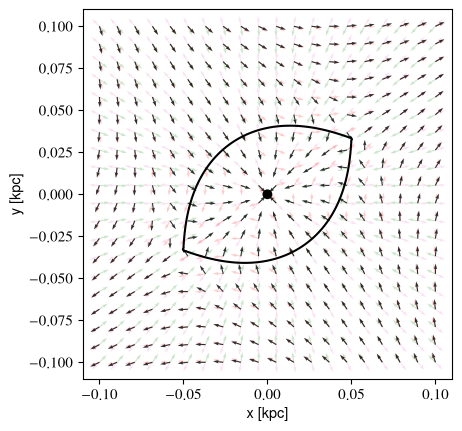

In [74]:
fig,axis=plt.subplots(1,1)
ellipse=patches.Ellipse([0,0],width=scaleRadius,height=scaleRadius,color="k")
line=axis.quiver(DX_VEC.flatten(),DY_VEC.flatten(),F_cen[:,0],F_cen[:,1],color="tab:pink",alpha=0.2,);
axis.quiver(DX_VEC.flatten(),DY_VEC.flatten(),F_tidal[:,0],F_tidal[:,1],color="r",alpha=0.2);
axis.quiver(DX_VEC.flatten(),DY_VEC.flatten(),F_gc[:,0],F_gc[:,1],color="g",alpha=0.2);
axis.quiver(DX_VEC.flatten(),DY_VEC.flatten(),F_tot[:,0],F_tot[:,1],color="k",alpha=0.8);
axis.contour(DX, DY, Phi, levels=[EL1[0]], colors="k",linestyle="-")

axis.add_patch(ellipse,)
axis.set(aspect="equal", ylabel = "y [kpc]", xlabel= "x [kpc]", );

build the points in spherical sheels instead for finding the zeros along each radial direction 

In [ ]:
# the the points uniformly on the a sphere 
ntheta = 60; nphi = 120;
theta=numpy.arccos(numpy.linspace(-1,1,ntheta))
phi = numpy.linspace(0, 2*numpy.pi, nphi)
TH, PH = numpy.meshgrid(theta, phi, indexing="ij")
nhat = numpy.stack([numpy.sin(TH)*numpy.cos(PH),
                    numpy.sin(TH)*numpy.sin(PH),
                    numpy.cos(TH)], axis=-1).reshape(-1, 3)


In [112]:
def effective_energy_level_set_along_direction(radius,unitvec, Ej, Hess_cen, Hess_mw, pot_cluster):
    return (Phi_eff(radius*unitvec, Hess_cen, Hess_mw, pot_cluster) - Ej)[0]

In [146]:
EL1

array([-10.67902443])

In [150]:
def effective_energy_level_set_along_direction(radius,unitvec, Ej, Hess_cen, Hess_mw, pot_cluster):
    return (Phi_eff(radius*unitvec, Hess_cen, Hess_mw, pot_cluster) - Ej)[0]

radii=numpy.zeros(nhat.shape[0])
for i in range(nhat.shape[0]):
    result=root(effective_energy_level_set_along_direction, rJ, args=(nhat[i], EL1, Hess_cen, Hess_mw, pot_cluster))
    radii[i]=result.x[0]

In [123]:
radii=numpy.zeros(nhat.shape[0])
for i in range(nhat.shape[0]):
    result=root(effective_energy_level_set_along_direction, rJ, args=(nhat[i], EL1, Hess_cen, Hess_mw, pot_cluster))
    radii[i]=result.x[0]

In [ ]:
x, y, z = (a.reshape(TH.shape) for a in (x, y, z))

In [ ]:
from scipy.optimize import brentq

def jacobi_radii(nhat, E, Hess, G, M, a, rmax, nsamp=400):
    h = numpy.einsum('ni,ij,nj->n', nhat, Hess, nhat)
    rs = numpy.linspace(1e-6, rmax, nsamp)
    # f[k, n] = f(rs[k]) for ray n
    f = -G*M/numpy.sqrt(rs[:, None]**2 + a**2) + 0.5*h[None, :]*rs[:, None]**2 - E
    crossed = f > 0
    has_root = crossed.any(axis=0)
    k = crossed.argmax(axis=0)           # first index where f > 0
    radii = numpy.full(len(nhat), numpy.nan)
    for n in numpy.flatnonzero(has_root & (k > 0)):
        g = lambda r: -G*M/numpy.sqrt(r**2 + a**2) + 0.5*h[n]*r**2 - E
        radii[n] = brentq(g, rs[k[n]-1], rs[k[n]], xtol=1e-12)
    return radii, h

radii, h = jacobi_radii(nhat, EL1[0], Hess_cen+Hess_mw, G, massCluster, scaleRadius, rJ, nsamp=400)

In [164]:
x, y, z = (radii[:, None]*nhat).T
x, y, z = (a.reshape(TH.shape) for a in (x, y, z))

[None]

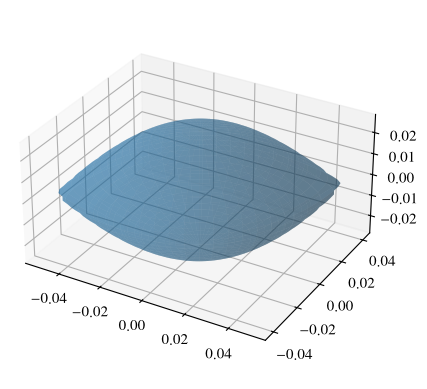

In [167]:

fig = plt.figure(); ax = fig.add_subplot(projection="3d")
ax.plot_surface(x, y, z, alpha=0.4)
ax.set_box_aspect((1, 1, 1))
ax.set(aspect="equal")

In [81]:
# get the energy at L1
Phi_eff(rJ*nhat[200],Hess_cen,Hess_mw,pot_cluster)

# get the total potential along a direction 

# and then find the sign change with the desired energy 


array([14.35263908])

now try the marching cubes


In [58]:
from skimage import measure
verts, faces, normals, values = measure.marching_cubes(pot_eff_3D,EL1)

[None]

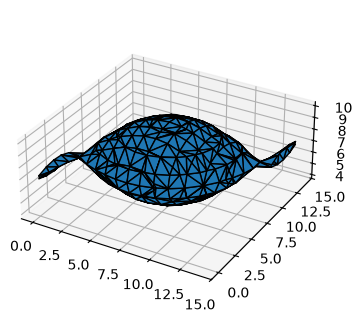

In [61]:
fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(111, projection='3d')

# Fancy indexing: `verts[faces]` to generate a collection of triangles
mesh = Poly3DCollection(verts[faces])
mesh.set_edgecolor('k')
ax.add_collection3d(mesh)


ax.set(aspect="equal")